# DSP Activity 4: Bills Counting using HSV

Same workflow as **Activity 2**, but using the HSV color space instead of RGB.

Put `bills.png` in the same folder as this notebook (or change the file name below).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening, closing

# Activity 4: Bills Counting using HSV

## 4.1 Load the image and convert to HSV

In HSV (OpenCV ranges: **H** 0-179, **S** 0-255, **V** 0-255) each bill has its own **hue**, which is much easier to use than RGB:

| Bill | Main color | Hue range (H) |
|---|---|---|
| 1000 | Blue | 90 - 125 |
| 500 | Yellow | 18 - 35 |
| 200 | Green | 36 - 85 |
| 100 | Purple | 126 - 160 |
| 50 | Red | 0 - 5 and 165 - 179 |
| 20 | Orange | 6 - 17 |

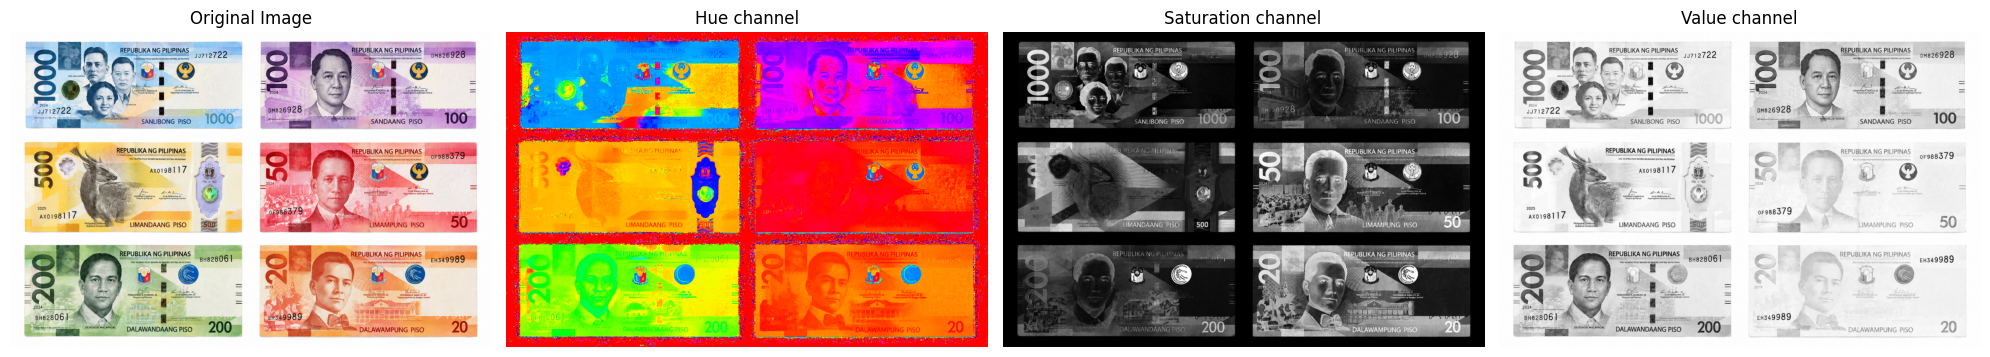

In [2]:
bills = cv2.imread('bills.png')
if bills is None:
    raise FileNotFoundError("Image not found.")

bills_rgb = cv2.cvtColor(bills, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(bills, cv2.COLOR_BGR2HSV)
Hmat, Smat, Vmat = cv2.split(hsv)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
axs[0].imshow(bills_rgb);          axs[0].set_title("Original Image")
axs[1].imshow(Hmat, cmap='hsv');   axs[1].set_title("Hue channel")
axs[2].imshow(Smat, cmap='gray');  axs[2].set_title("Saturation channel")
axs[3].imshow(Vmat, cmap='gray');  axs[3].set_title("Value channel")
for a in axs: a.axis("off")
plt.tight_layout()
plt.show()

## 4.2 Separate the bills from the background

The background is white: **low saturation and high value**. Everything else is a bill.

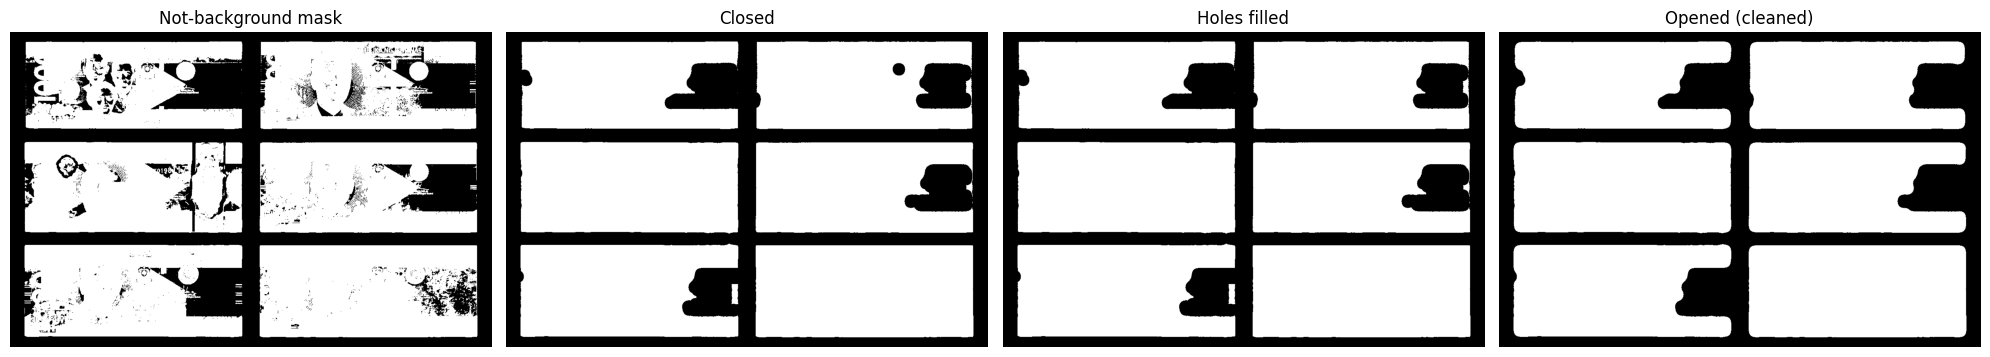

Number of bills found: 6
98026.0
100583.0
119768.0
103683.0
107412.0
122457.0


In [3]:
# Background = low saturation AND high brightness
background = (Smat < 25) & (Vmat > 225)
bills_mask = (~background).astype(np.uint8)

# Close small gaps (white areas inside the bills)
closed = closing(bills_mask, disk(15)).astype(np.uint8)

# Fill holes
flood_fill = (closed * 255).astype(np.uint8)
h, w = flood_fill.shape
mask = np.zeros((h+2, w+2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled = cv2.bitwise_or(closed * 255, cv2.bitwise_not(flood_fill))

# Morphological opening
opened = opening(filled // 255, disk(15)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = [r for r in regionprops(label_image) if r.area > 5000]

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for a, im, t in zip(axs, [bills_mask, closed, filled, opened],
                    ["Not-background mask", "Closed", "Holes filled", "Opened (cleaned)"]):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()

print("Number of bills found:", len(regions))
for region in regions:
    print(region.area)

## 4.3 Identify each bill by its hue

For every bill region we take its **saturated pixels** and count how many fall in each color's hue range (like the `cv2.inRange` masks in Activity 2). The color with the most pixels decides the denomination.

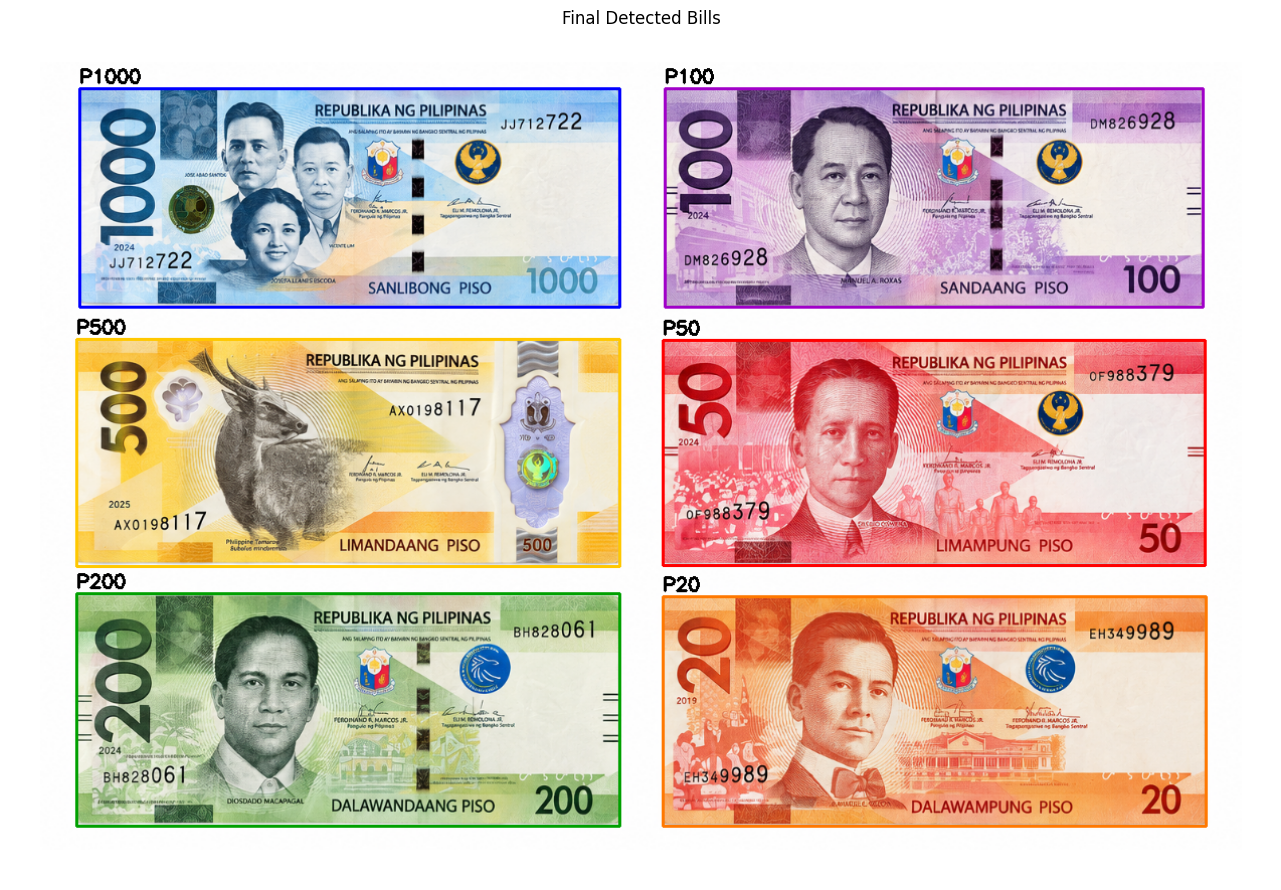

 P1000: 1
  P500: 1
  P200: 1
  P100: 1
   P50: 1
   P20: 1
Total bills: 6
Total value: PHP 1870


In [4]:
# name: (list of (Hlow, Hhigh) ranges, peso value, box color RGB)
bill_types = {
    'P1000': ([(90, 125)],            1000, (0, 0, 255)),
    'P500':  ([(18, 35)],             500,  (255, 200, 0)),
    'P200':  ([(36, 85)],             200,  (0, 160, 0)),
    'P100':  ([(126, 160)],           100,  (160, 0, 200)),
    'P50':   ([(0, 5), (165, 179)],   50,   (255, 0, 0)),
    'P20':   ([(6, 17)],              20,   (255, 120, 0)),
}

def identify_bill(region):
    region_mask = (label_image == region.label)
    colored = region_mask & (Smat > 60) & (Vmat > 80)      # only saturated pixels carry hue info
    best, best_count = None, -1
    for name, (ranges, value, color) in bill_types.items():
        count = sum(np.count_nonzero(colored & (Hmat >= lo) & (Hmat <= hi)) for lo, hi in ranges)
        if count > best_count:
            best, best_count = name, count
    return best

# Add white space around the image so labels fit above the boxes
pad = 30
output_img = cv2.copyMakeBorder(bills_rgb, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=(255, 255, 255))
found = {name: 0 for name in bill_types}
total_value = 0

for region in regions:
    name = identify_bill(region)
    value, color = bill_types[name][1], bill_types[name][2]
    found[name] += 1
    total_value += value
    minr, minc, maxr, maxc = region.bbox
    # shift coordinates by the padding
    minr, minc, maxr, maxc = minr + pad, minc + pad, maxr + pad, maxc + pad
    cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 2)
    # label placed ABOVE the bill
    cv2.putText(output_img, name, (minc, minr - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

fig, ax = plt.subplots(1, 1, figsize=(14, 9))
ax.imshow(output_img)
ax.set_title("Final Detected Bills")
ax.axis("off")
plt.tight_layout()
plt.show()

for name, n in found.items():
    print(f"{name:>6}: {n}")
print(f"Total bills: {sum(found.values())}")
print(f"Total value: PHP {total_value}")